> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/examples/two-fleets.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Two fleets in the Baltic

[Regional networks](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/examples/regional-networks.html) · deck `simulations/examples/example_3/`

How much do the owners' efficiency choices matter on the same trade?

## The case

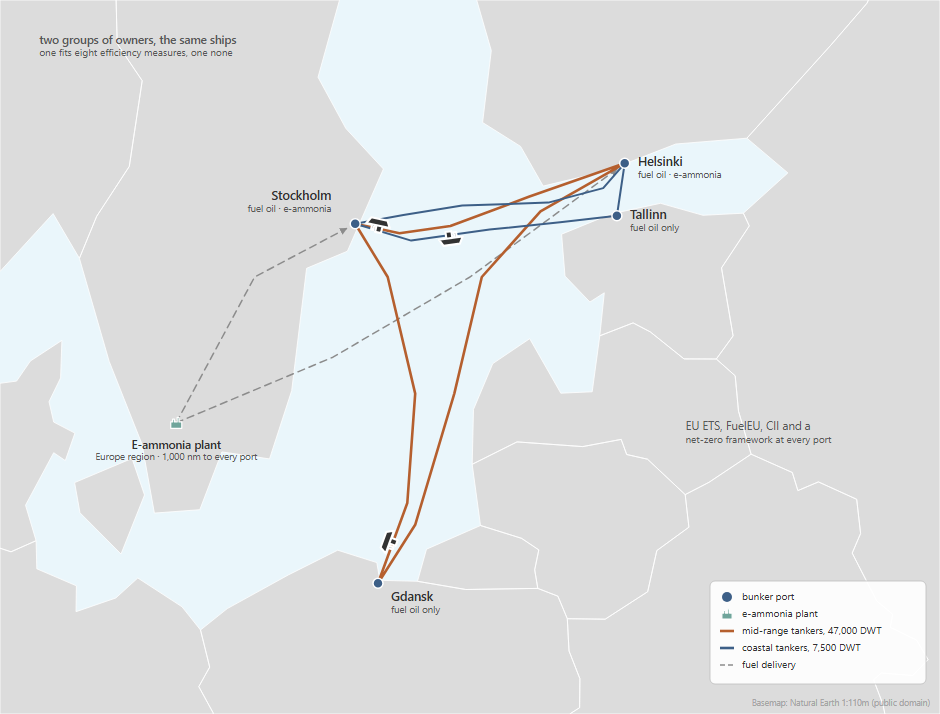

- **Ships:** product tankers in the Baltic, in two fleets that are the same in
  everything but one choice. The *regular* owners fit no efficiency measure; the
  *efficient* owners can fit eight (air lubrication, rotor sails, hull paint,
  propeller devices and others). Each fleet starts with 2 MR tankers
  (~47,000 DWT) and 3 coastal tankers (~7,500 DWT): a handful of ships, not a
  market segment.
- **Routes:** the MR tankers sail Helsinki, Stockholm and Gdansk; the coastal
  tankers Helsinki, Tallinn and Stockholm. Trade grows 5 % a year.
- **Fuels:** fuel oil everywhere; e-ammonia from a European plant, bunkered at
  Helsinki and Stockholm only.
- **Policy:** EU ETS and FuelEU on every port, CII, and a net-zero framework
  whose values are the deck's own, not the data library's.
- **Horizon:** 2026 to 2050, yearly.

## Results

In [1]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, even when the `navigate`
# command itself is missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# The example deck.
EXAMPLE = Path("simulations/examples/example_3")
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there."
)


Moved up to the repository root.
Navigate 1.0.0 is already installed.


The cell below solves the case from 2026 to 2050 and draws its well-to-wake emissions, its freight rate and the fuel it burns.

No technology cost of capital supplied for Fleet("mid_range_efficient"), using vessel cost of capital. This will likely lead to a higher uptake of technologies.
No technology cost of capital supplied for Fleet("coastal_efficient"), using vessel cost of capital. This will likely lead to a higher uptake of technologies.


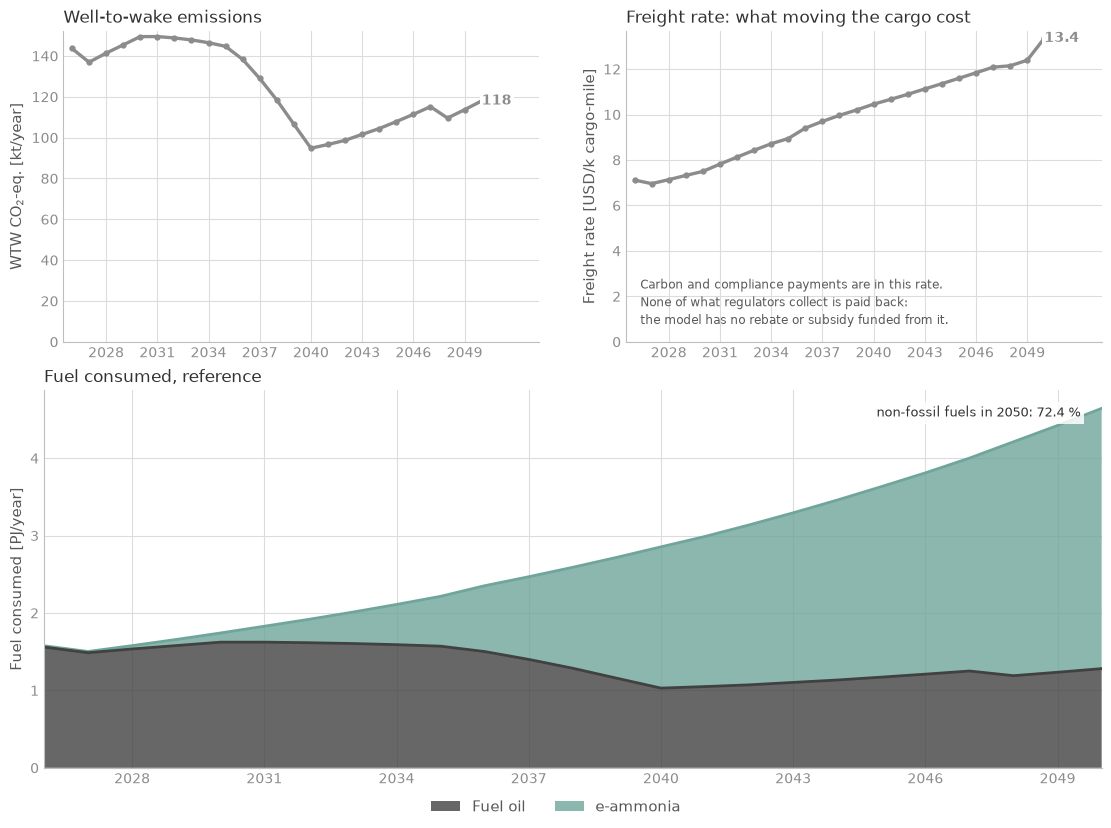

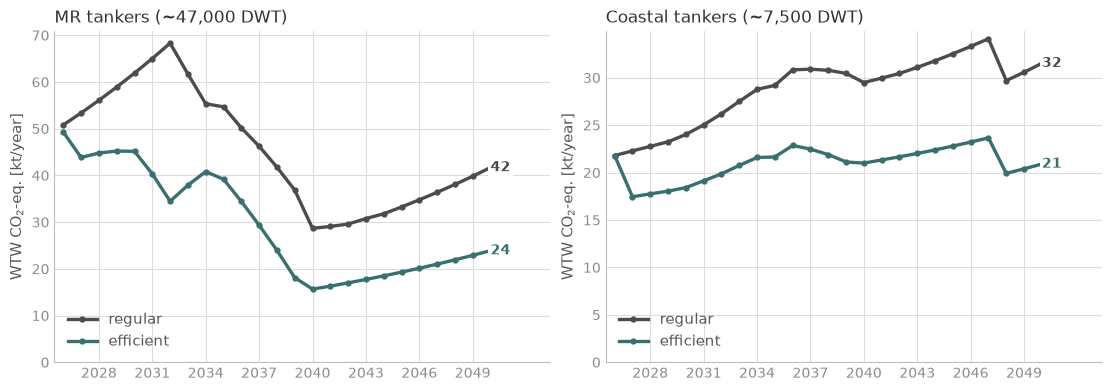

In [2]:
# @title Run the case and see the results
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# The workshop's figure and the functions that fill it, shared with the
# Examples pages: docs/workshop/_results.py.
sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _results import compare_with_previous, plot_cases, plot_fleet_emissions, print_summary, run_case, scale, summarise
from _solver import guard_interior_point

guard_interior_point()

NAV = Path("simulations/examples/example_3/example_3.nav")
REF_TWEAK = None
_m = run_case(NAV)
ref = summarise(_m)
plot_cases({"reference": ref}, annotate=True)
plt.show()

plot_fleet_emissions(_m, {
    "MR tankers (~47,000 DWT)": {"regular": "mid_range_regular",
                                 "efficient": "mid_range_efficient"},
    "Coastal tankers (~7,500 DWT)": {"regular": "coastal_regular",
                                     "efficient": "coastal_efficient"},
}, {"regular": "#4c4c4c", "efficient": "#377070"})
plt.show()


# ===========================================================================
#  The machinery for the sensitivity analysis. Nothing to edit here: the
#  levers are further down.
# ===========================================================================
# each lever, and the forecasts it multiplies
LEVERS = {
    "OIL_PRICE": ['fossil_fuel_oil_price_global'],
    "EU_ETS_PRICE": ['eu_ets_carbon_credit_price'],
    "EUROPE_ELECTRICITY_PRICE": ['electricity_cost_europe_mid'],
}
_RUNS = []      # the scenarios solved so far, newest last: (levers, summary)


def run_your_scenario():
    """Solve the levers set in the YOUR SCENARIO cell and compare with
    the reference and with the scenario solved before it."""
    changed = [(n, globals()[n]) for n in LEVERS if globals()[n] != 1.0]
    if not changed:
        print("Every lever is still at 1.0, so this would just re-solve the deck.")
        print("Change one of the numbers above and run this cell again.")
        return
    tweaks = ([REF_TWEAK] if REF_TWEAK else []) + [scale(f, v) for n, v in changed
                                                   for f in LEVERS[n]]

    def your_scenario(m):
        for t in tweaks:
            t(m)

    label = ",  ".join(f"{n} x {v}" for n, v in changed)
    compare_with_previous(NAV, ref, your_scenario, label, _RUNS, ref_label="reference")
    plt.show()


### Move one lever

Each number multiplies what the deck already says, so 1.0 is the reference. Set one, run the cell, and compare with the reference and with the scenario you ran before. As an example, OIL_PRICE is set to 2.0: the fuel oil price doubled.

No technology cost of capital supplied for Fleet("mid_range_efficient"), using vessel cost of capital. This will likely lead to a higher uptake of technologies.
No technology cost of capital supplied for Fleet("coastal_efficient"), using vessel cost of capital. This will likely lead to a higher uptake of technologies.


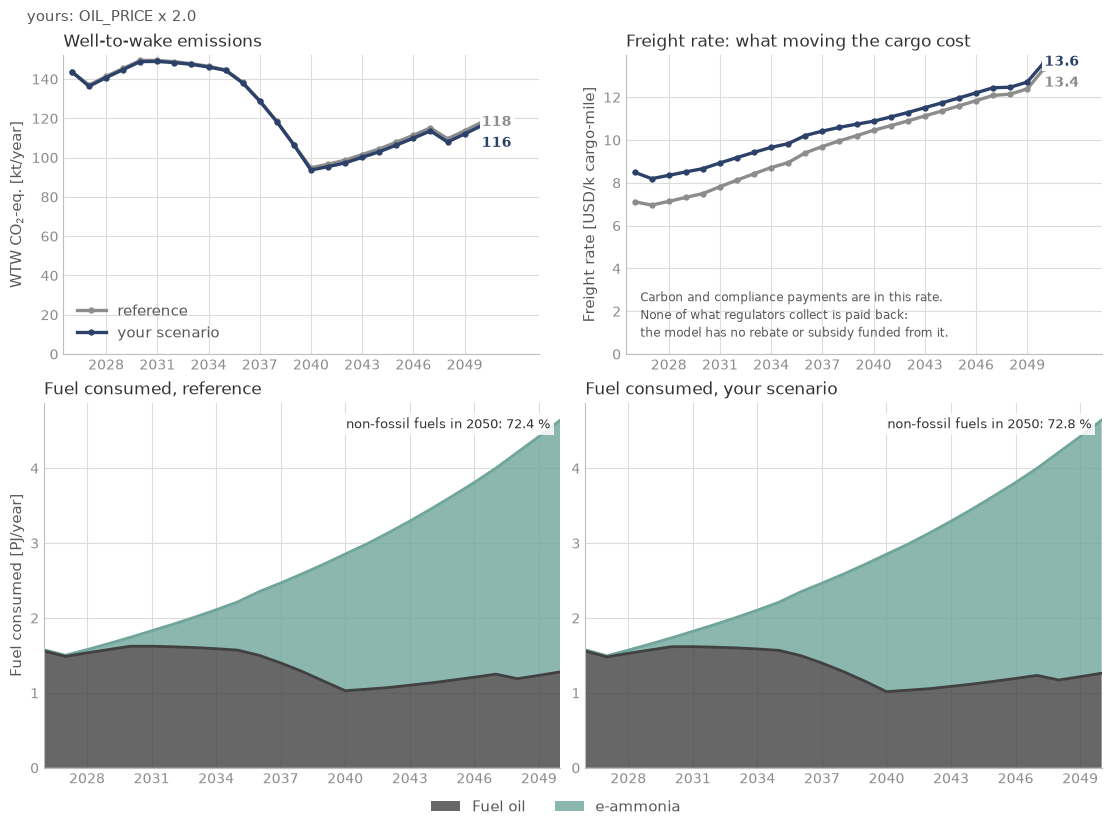

In [3]:
# ===========================================================================
#  YOUR SCENARIO.  Set a lever, then run this cell: it solves your scenario
#  and compares it with the reference and with the scenario you ran before it.
#
#  Every number is a MULTIPLIER on what the deck already says, so 1.0 is the
#  deck. The right-hand column says what each 1.0 is worth, so you can judge
#  whether a factor of two is a big change or a small one.
#
#  As an example, OIL_PRICE is set to 2.0: the fuel oil price doubled.
#  Set OIL_PRICE back to 1.0 to start from the deck.
#
#                                   suggested span  what 1.0 means in the deck
OIL_PRICE                = 2.0   #  0.7 - 2.0       485 USD/t, flat to 2050
EU_ETS_PRICE             = 1.0   #  0.5 - 3.0       126 USD/t in 2026, 417 by 2050
EUROPE_ELECTRICITY_PRICE = 1.0   #  0.6 - 1.4       72 USD/MWh in 2026, 53 by 2050: the power e-ammonia is made from
# ===========================================================================

run_your_scenario()


## The deck

In [4]:
# @title The deck, tab by tab
import sys
from pathlib import Path

sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _deck import show_deck

show_deck(EXAMPLE, {
    "example_3.nav": ['example_3.nav'],
    "Fleets": ['includes/regular_fleet.inc', 'includes/efficient_fleet.inc', 'includes/regular_fleet_curves.inc', 'includes/efficient_fleet_curves.inc'],
    "Route": ['includes/route.inc', 'includes/ports.inc', 'includes/bunker_logistics.inc'],
    "Fuel": ['includes/fuel_production.inc', 'includes/regions.inc', 'includes/producer.inc'],
    "Regulation": ['includes/cii.inc', 'includes/eu_ets.inc', 'includes/fuel_eu.inc', 'includes/net_zero_framework.inc'],
    "Decisions": ['includes/decision_processes.inc'],
})


# ---- example_3.nav ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# ---------------------------------------------------------------------------------
# SETTING THE SCENE – EXAMPLE 3 (BALTIC PRODUCT TANKERS WITH E-AMMONIA AND
# ENERGY EFFICIENCIES)
#
# This example is based in Helsinki and is modeled through two operators with
# similar fleets. Each operates a mix of MR tankers (~47k DWT) and coastal
# tankers (~7.5k DWT) trading across the Baltic Sea, with regular voyages linking
# Helsinki, Stockholm, Tallinn, and Gdansk.
#
# Both operators can use conventional fossil fuel or transition to
# e-ammonia as an alternative. Fuel availability is assumed to be uneven:
# Helsinki and Stockholm provide both fossil fuels and e-ammonia, while Tallinn
# and Gdansk supply fossil fuels only.
#
# The distinction lies in their adoption of energy-efficiency (EE) measures. One
# operator (EE_fleet) implements a package of EE measures (such as hull and
# propeller improvements, weather routing, and alternative power devices), while
# the other (regular_fleet) does not. This setup allows for a direct comparison
# of the economic and emissions impact of efficiency retrofits, under otherwise
# identical conditions.
#
# Operating within the European regulatory zone, the fleets are subject to both
# IMO measures (CII and potential NZF) and EU regulations (FuelEU
# Maritime and the EU ETS). These frameworks create strong incentives for
# reducing emissions through both fuel switching and efficiency improvements.
#
# This scenario provides a reference case for analyzing the combined and
# comparative impacts of e-ammonia adoption and energy-efficiency measures on
# short-sea tanker economics in the Baltic. Users can adjust fleet composition,
# efficiency uptake, fuel costs, and regulatory assumptions in the .inc files to
# test sensitivities and policy outcomes.
#
# ---------------------------------------------------------------------------------

DEFINE {

    # -------------------------- DEFINITIONS --------------------------
    # Import the default model settings. These provide baseline constants
    # and parameters that can be overwritten in this scenario.
    Load DefaultModelDefinition

    # ---------------------------- FLEET ------------------------------
    # Defines the fleets of the two different operators, contaning multiple
    # tankers and similar vessel types, but differentiation on the EE-measures.
    Include "includes/regular_fleet_curves.inc"
    Include "includes/regular_fleet.inc"
    Include "includes/efficient_fleet_curves.inc"
    Include "includes/efficient_fleet.inc"

    # ----------------------------- ROUTE -----------------------------
    # Defines the ports included in the scenario (Helsinki, Stockholm, Tallinn, 
    # Gdansk) along with their characteristics. The route file specifies the 
    # distribution of voyages, port calls, and time allocation between sea 
    # and port conditions.
    Include "includes/route.inc"
    Include "includes/ports.inc"
    Include "includes/bunker_logistics.inc"

    # ----------------------------- FUEL ------------------------------
    # Defines the fuels available in the scenario, their production processes,
    # feedstocks, costs, and emission factors. Regional differences and
    # plants are also defined here. 
    Include "includes/fuel_production.inc"
    Include "includes/regions.inc"
    Include "includes/producer.inc"
    Load DefaultEmission

    # -------------------------- REGULATION ---------------------------
    # Defines the relevant international regulatory frameworks affecting the
    # fleet. As we operate within EU, both IMO and EU jurisdiction are in 
    # effect. 
    Include "includes/cii.inc"
    Include "includes/eu_ets.inc"
    Include "includes/fuel_eu.inc"
    Include "includes/net_zero_framework.inc"

    # ---------------- DECISION PROCESESS ---------------

## Build it with an AI assistant

The prompt below rebuilds this deck exactly: an assistant that saw only the
prompt reproduced its results to the tonne. The deck's own numbers are in it as
the person's numbers, marked GIVEN, so they are not a source.
[Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html) shows how to use it.

<details>
<summary>Full prompt for this case</summary>

<!-- tested-prompt: 6b917359e6c0 -->
**The study.** Product tankers in the Baltic, 2026 to 2050, owned by two groups
of owners with the same ships on the same trades: mid-range tankers (47,000 DWT)
between Helsinki, Stockholm and Gdansk, and coastal tankers (7,500 DWT) between
Helsinki, Tallinn and Stockholm. The ships burn fuel oil or e-ammonia made in
Europe, which only Helsinki and Stockholm sell. One group fits eight efficiency
measures, the other none; both are under CII, a net-zero framework, the EU ETS
and FuelEU. The question is how much the efficiency measures change their fuel
and their emissions. This prompt rebuilds `simulations/examples/example_3`
exactly. The "Two fleets, one market" variant of the copper trade asks the same
question on one trade of your choice, with library numbers.

**What comes from the library.** The two tanker classes (oil and ammonia
designs), the eight efficiency measures, the fuels and the fuel oil price, the
e-ammonia plant and its processes, Europe's electricity price, the EU ETS carbon
price and phase-in, FuelEU's target and penalty, and the EU default emission
factors.

**What is GIVEN.** Everything else is example_3's own: the fleet sizes and ages,
the routes, the ports' fuels and handling costs, the bunker delivery, the plant
capacity, the CII and net-zero framework targets, and the decision
sensitivities. The prompt gives them as the person's numbers, so the assistant
uses them as they are and marks them GIVEN. They exist nowhere in the library:
treat any result as the example's, not the Baltic's.

**Limits.** A few ships per group (two mid-range and three coastal tankers each
in 2026), so the results come in fractions of ships. Both tanker sizes fit the
library's measures for a 35,000 DWT tanker.

**Tested:** 2026-10-30, built cold on Sonnet and on Haiku: both decks ran with
the same 48 warnings as example_3 (two unique, both expected) and reproduce it to
the tonne, fleet by fleet. The plant then gained the library's cost of capital
(it was financed at 0 %); built cold again on Haiku, the prompt reproduces the
new deck to the tonne: 143,662 t CO2e in 2026, 144,697 t in 2035 and 117,990 t
in 2050, when e-ammonia is 72 % of the energy burnt. In 2050 the efficient
group emits 45 kt against 73 kt for the regular one.

````text
You are helping me build a simulation study for Navigate, the shipping
decarbonisation model. Write the files yourself; do not only
describe them.

Before writing anything, find the Navigate repository on my machine (a folder
usually named navigate-zcs; ask me where it is if you cannot find it), then read
docs/workshop/building-a-deck.md in it and follow it. It
says how Navigate works, how to run a deck and read its results, and the rules
every deck follows. This prompt gives the case.

THE DECK
A new folder, simulations/user/baltic_tankers/, holding one deck,
baltic_tankers.nav, with its files in includes/.

THE CASE
Product tankers in the Baltic, 2026 to 2050, yearly steps. Two groups of
owners run the same ships on the same trades: one group fits eight efficiency
measures, the other fits none. The question: how much do the efficiency
measures change their fuel and their emissions?

MY NUMBERS
Every number in this prompt is mine: GIVEN. Use each one exactly as written,
mark it GIVEN where it appears, and list them in the .nav header. The fleets are
a few ships on purpose. You should not need to invent anything; if you would
have to, the prompt is missing something: say what. Everything else comes from
the library, by the names below.

THE .NAV FILE
DEFINE, in this order: Load DefaultModelDefinition; Include
regular_fleet_curves.inc, regular_fleet.inc, efficient_fleet_curves.inc,
efficient_fleet.inc, route.inc, ports.inc, bunker_logistics.inc,
fuel_production.inc, regions.inc, producer.inc; Load DefaultEmission; Include
cii.inc, eu_ets.inc, fuel_eu.inc, net_zero_framework.inc,
decision_processes.inc; Load DefaultPlot. EVENTS: Load DefaultTimeStepYearly.
Load no other module (no DefaultRegulation, DefaultBunkerLogistics,
DefaultCalibration or DefaultConverterAvailable). For the numbers below you may
add Load DefaultReport and a Report node of your own in includes/report.inc,
included last: they change no result.

FLEETS
Four Fleet nodes that you declare yourself; do not Import or Copy the library's
Fleet files (so no fuel conversion costs and no initial technology shares).
Vessels are Copy Vessel of the library's:
- tanker_47k_dwt_ice_oil to mid_range_regular_oil and mid_range_efficient_oil
- tanker_47k_dwt_ice_ammonia to mid_range_regular_ammonia and
  mid_range_efficient_ammonia
- tanker_7500_dwt_ice_oil to coastal_regular_oil and coastal_efficient_oil
- tanker_7500_dwt_ice_ammonia to coastal_regular_ammonia and
  coastal_efficient_ammonia

| Fleet | Vessels | InitialVessels | InitialSplit | InitialAgeDistribution |
|---|---|---|---|---|
| mid_range_regular | mid_range_regular_oil, _ammonia | 2 | [0.5, 0.5] | Curve age_dist_mid_range_regular_oil, Curve age_dist_mid_range_regular_ammonia |
| coastal_regular | coastal_regular_oil, _ammonia | 3 | [1.0, 0.0] | Curve age_dist_coastal_regular_oil, 0 |
| mid_range_efficient | mid_range_efficient_oil, _ammonia | 2 | [0.5, 0.5] | Curve age_dist_mid_range_efficient_oil, Curve age_dist_mid_range_efficient_ammonia |
| coastal_efficient | coastal_efficient_oil, _ammonia | 3 | [1.0, 0.0] | Curve age_dist_coastal_efficient_oil, 0 |

- All four: TradeGrowth = 0.05.
- The two regular fleets also: AllowTechnologyApproximation = FALSE. The
  efficient fleets do not set it.
- Age curves, in <fleet>_curves.inc, each a Table of ages 0 to 24 with 0 at
  every age not named: the mid_range ..._oil curves 1 at age 16; the mid_range
  ..._ammonia curves 1 at age 0; the coastal ..._oil curves 0.333 at ages 6, 9
  and 14. The regular and efficient files are the same apart from the names.
- In efficient_fleet.inc, after the two fleets, one block Fleet "*_efficient"
  with Technologies = the library's air_lubrication_tanker_35k_dwt,
  cargo_systems_tanker_35k_dwt, exhaust_gas_boiler_ae_tanker_35k_dwt,
  flettner_rotor_tanker_35k_dwt, hull_painting_tanker_35k_dwt,
  lighting_system_tanker_35k_dwt, propeller_improvement_devices_tanker_35k_dwt,
  variable_frequency_drive_tanker_35k_dwt (as Technology("...")). The regular
  fleets have no Technologies.

ROUTES (route.inc)
Vessel "mid_range_*" takes Route("mid_range_route"); Vessel "coastal_*" takes
Route("coastal_route"). Both are REGIONAL_TRIP:
- mid_range_route: Ports helsinki, stockholm, gdansk; PortCalls [12, 10, 14];
  TimeAtSea 0.55; Speeds [12.8, 13.0, 12.5]; ConditionDistribution
  [0.34, 0.28, 0.38]
- coastal_route: Ports helsinki, tallinn, stockholm; PortCalls [14, 12, 10];
  TimeAtSea 0.40; Speeds [11.5, 11.0, 11.2]; ConditionDistribution
  [0.40, 0.30, 0.30]
No set_voyage_distribution: the work is split equally between port pairs.

PORTS (ports.inc)
Declare Port helsinki, stockholm, tallinn and gdansk. ammonia_electro may be
bunkered at helsinki and stockholm, not at tallinn and gdansk. Then a Port "*"
block: fossil_fuel_oil may be bunkered everywhere, its bunker price overwritten
by Forecast fossil_fuel_oil_price_global and its carbon_dioxide well-to-tank by
Forecast fossil_fuel_oil_wtt_carbon_dioxide (set_bunker_price_overwrite,
set_bunker_wtt_overwrite); handling cost Variable handling_cost_oil = 8 for
fossil_fuel_oil and Variable handling_cost_ammonia = 25 for ammonia_electro.

BUNKER LOGISTICS (bunker_logistics.inc)
LiquidMarketFuels = fossil_fuel_oil; set_distance("*", "*", 1000);
set_transport_cost("*", 0.1).

FUEL (fuel_production.inc, regions.inc, producer.inc)
- Import Fuel fossil_fuel_oil and ammonia_electro; Import Plant
  plant_ammonia_electro_alkaline, then a Plant block for it with
  Region = Region("europe"), Source = Source("renewable") and CostOfCapital =
  Forecast("cost_of_capital_plant_electro_europe"). Import Process electrolysis_stack_alkaline,
  ammonia_synthesis_electro_alkaline, hydrogen_electro_alkaline and
  nitrogen_air_separation; Import Feedstock demineralized_water; Import Source
  renewable.
- Region "europe", declared (not imported), with exactly these lines:
  feedstock cost of demineralized_water = Forecast demineralized_water_cost;
  source opex of renewable = Forecast electricity_cost_europe_mid; for
  electrolysis_stack_alkaline and for hydrogen_electro_alkaline, process capex
  and opex = Timetables <process>_capex and <process>_opex, and process energy,
  lifetime and replacement = Forecasts <process>_energy, _lifetime and
  _replacement; for "ammonia_synthesis_electro_*", process capex and opex =
  Timetables ammonia_synthesis_capex and ammonia_synthesis_opex, and process
  energy = Forecast ammonia_synthesis_energy.
- Producer epc_europe: Plants = plant_ammonia_electro_alkaline,
  InitialCapacity = [108], MaximumDevelopment = 1. No feedstock limits.

POLICY
All four regulations: Fuels all, Jurisdiction [helsinki, stockholm, gdansk,
tallinn], set_include_vessel("*", TRUE).
- cii.inc, Regulation cii: Measure TRANSPORT_NOMINAL, Scheme INDIVIDUAL, Scope
  TTW, IncludeSlip FALSE, Emissions carbon_dioxide, RemedialCost 0; fuel TTW
  carbon_dioxide 3.114 for fossil_fuel_oil and 0.054 for ammonia_electro;
  vessel threshold Forecast cii_target_coastal for "coastal_*" and
  cii_target_mid_range for "mid_range_*". Forecast cii_target_reduction:
  2019 1.0, 2020 0.99, 2021 0.98, 2022 0.97, 2023 0.95, 2024 0.93, 2025 0.91,
  2026 0.89, 2027 0.87, 2028 0.85, 2029 0.83, 2030 0.81 (each on 01-01),
  Extrapolate FLAT. Copy Forecast it to cii_target_coastal (Multiplier 22.71)
  and to cii_target_mid_range (Multiplier 7.41).
- eu_ets.inc, Regulation eu_ets, declared (not the library's): Measure ABSOLUTE,
  Scheme INDIVIDUAL, Scope TTW, IncludeSlip FALSE, Emissions carbon_dioxide,
  methane, nitrous_oxide; IntraFraction 1, InterFraction 0.5, ExtraFraction 0;
  RemedialCost = Forecast eu_ets_carbon_credit_price x Forecast
  eu_ets_maritime_phase_in; vessel threshold 0 for "*"; global warming
  potentials 1, 28, 265. Fuel TTW: fossil_fuel_oil carbon_dioxide = Variable
  eu_default_diesel_carbon_dioxide; for both fossil_fuel_oil and
  ammonia_electro, methane = Variable eu_default_diesel_ice_methane x Forecast
  eu_ets_ghg_phase_in and nitrous_oxide = Variable
  eu_default_diesel_ice_nitrous_oxide x Forecast eu_ets_ghg_phase_in;
  ammonia_electro carbon_dioxide 0.
- fuel_eu.inc, Regulation fuel_eu, declared (not the library's): Measure
  INTENSITY, Scheme FLEXIBLE, Scope WTW, IncludeSlip FALSE, Emissions
  carbon_dioxide, methane, nitrous_oxide; IntraFraction 1, InterFraction 0.5,
  ExtraFraction 0; RemedialCost = Variable fuel_eu_remedial_cost;
  SharedThreshold = Forecast fuel_eu_target_reduction; global warming
  potentials 1, 25, 298. fossil_fuel_oil: well-to-tank "*" set to 0, then
  carbon_dioxide = Variable fuel_eu_default_wtt_fossil_fuel_oil; TTW
  carbon_dioxide, methane, nitrous_oxide = Variables
  eu_default_diesel_carbon_dioxide, eu_default_diesel_ice_methane,
  eu_default_diesel_ice_nitrous_oxide. ammonia_electro: TTW carbon_dioxide 0,
  methane and nitrous_oxide the same two Variables.
- net_zero_framework.inc, Regulation net_zero_framework: Measure INTENSITY,
  Scheme FLEXIBLE, Scope WTW, IncludeSlip TRUE, Emissions all; RemedialCost =
  Forecast net_zero_framework_remedial; SharedThreshold = Forecast
  net_zero_framework_z_values. Forecast net_zero_framework_z_values, Multiplier
  93.3, Extrapolate FLAT: 01-01-2025 1.00, 31-12-2027 1.00, 01-01-2028 0.96,
  01-01-2029 0.94, 01-01-2030 0.92, 01-01-2031 0.876, 01-01-2032 0.832,
  01-01-2033 0.788, 01-01-2034 0.744, 01-01-2035 0.70, 01-01-2040 0.35,
  01-01-2050 0.05. Forecast net_zero_framework_remedial, Extrapolate FLAT:
  01-01-2025 0, 31-12-2027 0, 01-01-2028 1000.

DECISIONS (decision_processes.inc)
Fleet "*": InterFuelSensitivity 0.5, IntraFuelSensitivity 0.5,
TechnologySensitivity 2. Producer epc_europe: FuelDemandSensitivity 1.25,
FuelCostSensitivity 0.5.

BEFORE YOU TELL ME IT WORKS
Run the deck and report on it as building-a-deck.md says: exit code, and the
warnings and errors from the Log summary. Then give me, for 2026, 2035 and 2050:
- well-to-wake emissions (TotalEquivalentWTW) of each of the four fleets, of
  each group of owners (regular, efficient) and of all four together;
- the energy consumed by fuel, all fleets together;
- the ships of each vessel in 2050.
Say plainly what the efficiency measures changed, for the mid-range and for the
coastal tankers.
````

</details>

The same question on one trade of your choice, with library numbers, is the
variant *Two fleets, one market* of the [trade route from Chile to
Rotterdam](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/examples/trade-route.html).

## Run it yourself

In Colab: the badge at the top of this page opens it as a notebook, which runs
the deck and lets you move the levers. Nothing to install.

On your machine, install Navigate first: follow the [installation steps in the README](https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/README.md#installation),
or the more detailed [Getting started](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/tutorials/getting_started.html) tutorial.
Then run the deck from the repository root:

```bash
python -m navigate simulations/examples/example_3/example_3.nav -d ./assumptions
```

To make a case of your own, copy the folder to `simulations/user/` and change
it, or have an AI assistant build one from the prompt above, as
[Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html) shows.